# Web scraping (basic)

## Conceptos de HTML

Para sacar el máximo partido a esta técnica es recomendable estar familiarizado o familiarizarse con el formato interno de las páginas web, es decir, conocer el formato [HTML](https://www.w3schools.com/html/) y las reglas CSS.

Para comenzar, hacemos aquí un breve (muy breve) repaso de HTML y del protocolo TCP/IP, ya que es indispensable conocerlo para entender la técnica de scraping. 

Se pondrán en práctica dos técnicas de scraping diferentes y las ejemplificaremos usando las librerías __Beautiful Soup__ y __Selenium__. 

## ¿Qué es?

 <div style='width: 500px;'/>

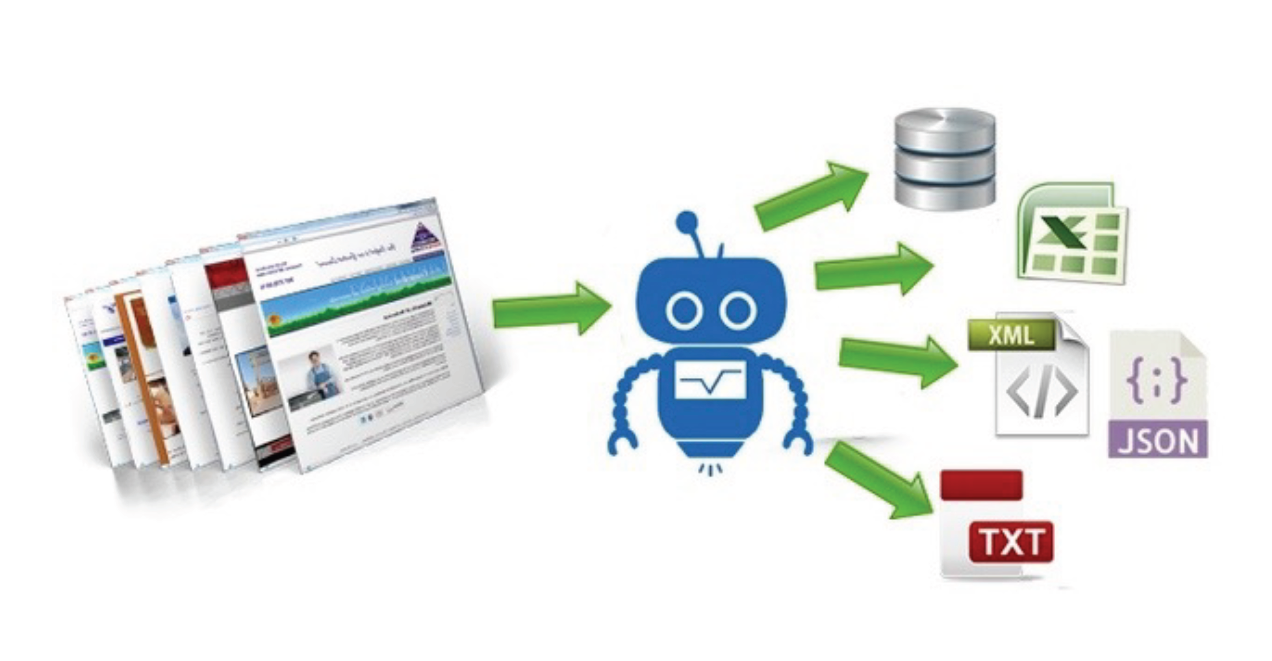

</div>

## ¿Cuándo?
<div style='width: 300px;'/>
</br>

</div>

<div style='width: 300px;'/>

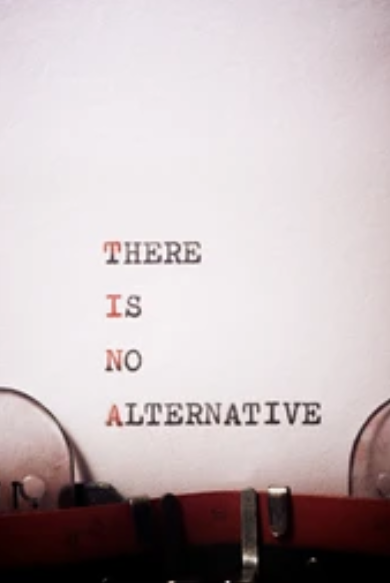

</div>


## Funcionamiento de la web

Los servidores son computadores que almacenan páginas web, sitios o aplicaciones. Cuando un dispositivo cliente quiere acceder a una página web, una copia de la página web se descarga desde el servidor en el equipo cliente y se muestra en el navegador web del usuario.

 <img src='./HTML_examples/peticion.png' style='width: 300px;'/>

* El navegador envía un mensaje de petición HTTP al servidor (url), pidiéndole que envíe una copia de la página web para el cliente. Este mensaje y todos los datos enviados entre el cliente y el servidor, se envían a través de tu conexión a Internet usando TCP/IP.
* Siempre que el servidor apruebe la solicitud del cliente, el servidor enviará al cliente un mensaje «200 OK», y comenzará a enviar los archivos de la página web al navegador como una serie de pequeños trozos llamados paquetes de datos.

* Un sitio web se compone de muchos archivos diferentes. Estos archivos se dividen en dos tipos principales:
    * Archivos de código: los sitios web se construyen principalmente con __HTML__, CSS y JavaScript.
    * Recursos: como imágenes, música, video, documentos de Word, archivos PDF, etc.

* El navegador reúne los pequeños trozos, forma un sitio web completo y te lo muestra.

## Archivos de códigos de las páginas web
### Documentos en formato HTML y XML

Los documentos HTML permiten definir la estructura de un sitio web mediante el uso de etiquetas. La estructura básica de los documentos HTML es la siguiente:

<img src="./images/estructura_html.PNG" alt="HTML_PAGES" style="width: 400px;"/>


__Ejemplo:__ https://quotes.toscrape.com/





__Listado de etiquetas `tags`__: https://www.w3schools.com/tags/default.asp


* La directiva  `<!DOCTYPE HTML>` indica que se trata de un documento HTML.
* La etiqueta (__tag__) `<html>` marca el comienzo del documento. Observar que la etiqueta `</html>` marca el fin del documento. 

* Los documentos HTML tienen __elementos__ de la forma:

```
<etiqueta atributo=‘valor’> contenido </etiqueta>

```

*  El atributo no es obligatorio, y una misma etiqueta puede tener más de uno.
* El elemento `<head> ... </head>` describe la cabecera del documento
* El elemento `<body> ... </body>` es el contenido de la página en sí, y el lugar donde normalmente encontraremos los datos que deseamos extraer.

### Las hojas de estilo CSS

Las CSS (holas de estilo en cascada), es un lenguaje que permite dar estilo a los distintos elementos que se definen en el documento HTML. Los navegadores son capaces de interpretar los documentos HTML junto con las reglas de formato CSS. En la siguiente imagen podemos ver cómo el navegador muestra el sitio web a partir de un documento HTML y su CSS.

<img src="./images/htmlcss.PNG" alt="HTML_css" style="width: 500px;"/>

### Ejemplo 

Para comenzar vamos a trabajar con una página web estática muy sencilla. Puedes verla pinchando en el siguiente enlace: [ejemplo.html](./HTML_examples/example.html)

* La página web tiene asociado un documento en formato HTML (a la derecha en la figura).
* Los navegadores (FireFox, Chrome, etc. ) reciben el documento HTML y lo interpretan mostrando la página web. 
* Un documento HTML describe la estructura y la apariencia de la página web.


<img src="./HTML_examples/html_web.png" alt="HTML_PAGES" style="width: 700px;"/>

### Estructura en forma de árbol

Una característica que tienen los documentos HTML es que se pueden representar mediante una estructura en forma de árbol, donde cada elemento del árbol (tag) representa una parte del documento.

* Cada elemento está contenido en otro elemento (su padre), excepto la raíz.
* Cada elemento puede contener otros elementos (sus hijos)

![dimagen](./HTML_examples/DOM.png)

Como podemos ver en la figura, hay dos tipos de elementos: los elementos sombreados y los elementos de texto. Estos últimos nunca tienen hijos.

Conocer la estructura del árbol nos ayudará a buscar y seleccionar la información que aparece en la página web.


## Tipos de sitios web

La forma en la que vamos a realizar scraping depende de las características del sitio web. La forma y características del sitio web marca las librerías de Python que tendremos que utilizar para la captura de datos.

__Sitios web estáticos__

Al poner la URL en el navegador obtenemos la información como parte de la página obtenida. A su vez, puede que los datos que nos interese capturar sean parte de la página, en cuyo caso usaremos la librería `BeautifulSoup`. 


__Sitios web Dinámicos__

En algunos casos el sitio web incluye un formulario que se debe rellenar para llegar a la página con los datos, o existe un botón que permite visualizar más resultados. Por lo general, es necesario el uso de la librería `Selenium` para moverse por este tipo de páginas. Veremos que se puede trabajar con ambas librerías (`BeautifulSoup` y `Selenium`) para la recolección de datos.

## Scraping con Beautiful Soup

In [51]:
from bs4 import BeautifulSoup
import requests
#import pandas as pd

`BeautifulSoup` es una librería para extraer información de documentos  HTML o XML. Permite navegar por el árbol del documento, extraer datos, modificar dicho árbol, etc. Aquí está la [documentación completa de Beautiful Soup 4.](https://www.crummy.com/software/BeautifulSoup/bs4/doc/).


Para comenzar vamos a trabajar con una página web estática muy sencilla. Puedes verla pinchando en el siguiente enlace: [ejemplo.html](./HTML_examples/example.html)

<img src="./HTML_examples/html_web.png" alt="HTML_PAGES" style="width: 800px;"/>


![dimagen](./HTML_examples/DOM.png)

Para mostrar su funcionamiento con nuestra página de juguete, lo primero que tenemos que hacer es crear un objeto de la clase `BeautifulSoup` que representa el documento HTML:

In [52]:
# Primer paso:
# carga de la página web de prueba en memoria : (carga del documento html)
with open("./HTML_examples/example.html") as html_doc:
    soup = BeautifulSoup(html_doc, 'html.parser')

* La variable `html_doc` contiene el texto interno de la página web. Buscar la información directamente en este documento puede ser muy laborioso. 
* El objeto `soup` de la clase `BeautifulSoup` es un árbol de elementos con la estructura que hemos visto arriba.
* Como segundo argumento de la constructora  `BeautifulSoup` usamos el valor `html.parser` para indicar que se debe utilizar el analizador sintáctico `parser` de `html`. Otro analizador sintáctico más potente, aunque más lento es `html5lib`.


Ejecutando el método `prettify()` podemos ver dicha estructura:

In [53]:
soup

<html>
<head>
<title>Recipes</title>
</head>
<body>
<h1>Over 100 Quick and Easy Recipes</h1>
<p class="intro">
		The majority of recipes we offer can be both prepared and cooked in 30 minutes or less, 
		from start to finish. Examples are
		<a class="breakfast desserts" href="http://example.com/Breakfast ">Breakfast</a>, 
		<a class="salad" href="http://example.com/salad">Salad Entrees</a> and
		<a class="salad soups" href="http://example.com/soup">Soups </a>.		
	  </p>
<p class="listado">
<h3 id="vbreakfast">Breakfast</h3>
<p class="info">Try this easy-to-prepare version for a breakfast.</p>
<ul class="vbreakfast">
<li><a href="http://example.com/breakfast_huevos">10-Minute Huevos Rancheros</a></li>
<li><a href="http://example.com/breakfast_bagel">Breakfast Bagel</a></li>
<li><a href="http://example.com/breakfast_poached_huevos">Poached Huevos</a></li>
</ul>
<h3 id="vsalad">Salad Entrees</h3>
<p class="info">The spicy dressing with adds a little extra zest to this salads.</p>
<ul clas

In [54]:
print(soup.prettify())

<html>
 <head>
  <title>
   Recipes
  </title>
 </head>
 <body>
  <h1>
   Over 100 Quick and Easy Recipes
  </h1>
  <p class="intro">
   The majority of recipes we offer can be both prepared and cooked in 30 minutes or less, 
		from start to finish. Examples are
   <a class="breakfast desserts" href="http://example.com/Breakfast ">
    Breakfast
   </a>
   ,
   <a class="salad" href="http://example.com/salad">
    Salad Entrees
   </a>
   and
   <a class="salad soups" href="http://example.com/soup">
    Soups
   </a>
   .
  </p>
  <p class="listado">
   <h3 id="vbreakfast">
    Breakfast
   </h3>
   <p class="info">
    Try this easy-to-prepare version for a breakfast.
   </p>
   <ul class="vbreakfast">
    <li>
     <a href="http://example.com/breakfast_huevos">
      10-Minute Huevos Rancheros
     </a>
    </li>
    <li>
     <a href="http://example.com/breakfast_bagel">
      Breakfast Bagel
     </a>
    </li>
    <li>
     <a href="http://example.com/breakfast_poached_huevos">
  

### Ejemplos de búsquedas con selectores  `select `  y  `select_one`

La función __select()__ de `BeautifulSoup`  permite buscar elementos en una página HTML utilizando selectores CSS. Estos selectores  permiten acceder a elementos por sus clases, identificadores (id), nombres de etiqueta, atributos y más.

https://www.w3schools.com/cssref/css_selectors.php

En este enlace podéis probar los distintos tipos de selectores: https://www.w3schools.com/cssref/trysel.php

__Ejemplo de búsqueda de elementos:__

In [55]:
# Buscar todos los elementos de tipo h1 en el sitio web
titulos_h3 = soup.select('h3')
titulos_h3

[<h3 id="vbreakfast">Breakfast</h3>,
 <h3 id="vsalad">Salad Entrees</h3>,
 <h3 id="vsalad">Traditional Salads</h3>]

In [56]:
# Buscar todos los elementos de tipo h1 en el sitio web
titulos_h3 = soup.select('h3')
for t in titulos_h3:
    print(t.get_text())

Breakfast
Salad Entrees
Traditional Salads


In [57]:
titulos_h3

[<h3 id="vbreakfast">Breakfast</h3>,
 <h3 id="vsalad">Salad Entrees</h3>,
 <h3 id="vsalad">Traditional Salads</h3>]

In [58]:
# Buscar todos los elementos de tipo h1 en el sitio web
soup.select_one('h1').get_text()

'Over 100 Quick and Easy Recipes'

__Ejemplo de búsqueda de una determinada clase:__

Usamos la notación `soup.select('.description')` para seleccionar el elemento que tiene 
la clase description. Los selectores CSS utilizan el prefijo . para indicar clases.

In [59]:
# Buscar todos los elementos que tienen class = vbreakfast
soup.select('ul.vbreakfast')

[<ul class="vbreakfast">
 <li><a href="http://example.com/breakfast_huevos">10-Minute Huevos Rancheros</a></li>
 <li><a href="http://example.com/breakfast_bagel">Breakfast Bagel</a></li>
 <li><a href="http://example.com/breakfast_poached_huevos">Poached Huevos</a></li>
 </ul>]

In [60]:
# Buscar todos los elementos que tienen class = vbreakfast
soup.select('ul.vsalad')

[<ul class="vsalad">
 <li><a href="http://example.com/salad_1">Healthy Veggie Salad</a></li>
 <li><a href="http://example.com/cheese_salad_2">Mexican Cheese Salad</a></li>
 </ul>,
 <ul class="vsalad">
 <li><a href="http://example.com/veggie_salad_3">Healthy Veggie Salad</a></li>
 <li><a href="http://example.com/mex_salad_4">Mexican Cheese Salad</a></li>
 </ul>]

__Ejemplo:__

Buscar elementos de tipo `p ` con `class = 'info'  `

In [61]:
# Selección de elementos por selector 'class' 
infos = soup.select('p.info')
infos

[<p class="info">Try this easy-to-prepare version for a breakfast.</p>,
 <p class="info">The spicy dressing with adds a little extra zest to this salads.</p>,
 <p class="info">Other principal salads.</p>]

In [62]:
for elemento in infos:
    print (elemento.get_text())

Try this easy-to-prepare version for a breakfast.
The spicy dressing with adds a little extra zest to this salads.
Other principal salads.


__Ejemplo de selección de elementos anidados:__

Extraer todos los enlaces de las recetas de tipo Breakfast. Dichos enlaces se encuentran dentro de una etiqueta de tipo `ul`con `class=vbreakfast`. Los enlaces están dentro de la etiqueta `a` :

In [63]:
#Selección de los hijos con etiqueta `a` del tag `ul` con atributo 'class' =  'vbreakfast'
elementos_breakfast = soup.select('ul.vbreakfast a' )
elementos_breakfast

[<a href="http://example.com/breakfast_huevos">10-Minute Huevos Rancheros</a>,
 <a href="http://example.com/breakfast_bagel">Breakfast Bagel</a>,
 <a href="http://example.com/breakfast_poached_huevos">Poached Huevos</a>]

In [64]:
# recuperar el enlace de cada uno de los hijos
for elem in elementos_breakfast:
    enlace = elem.get('href')
    print(enlace)

http://example.com/breakfast_huevos
http://example.com/breakfast_bagel
http://example.com/breakfast_poached_huevos


__Ejemplo de selección por id:__

In [65]:
main_content = soup.select('#vsalad')
main_content

[<h3 id="vsalad">Salad Entrees</h3>, <h3 id="vsalad">Traditional Salads</h3>]

In [66]:
for e in main_content:
    print(e.get_text())

Salad Entrees
Traditional Salads


__Ejemplo de selección por atributos:__

In [67]:
# Seleccionar los elementos con etiqueta `a` que tengan un atributo llamado 'href'
elementos_breakfast = soup.select('a[href]' )
list(elementos_breakfast)

[<a class="breakfast desserts" href="http://example.com/Breakfast ">Breakfast</a>,
 <a class="salad" href="http://example.com/salad">Salad Entrees</a>,
 <a class="salad soups" href="http://example.com/soup">Soups </a>,
 <a href="http://example.com/breakfast_huevos">10-Minute Huevos Rancheros</a>,
 <a href="http://example.com/breakfast_bagel">Breakfast Bagel</a>,
 <a href="http://example.com/breakfast_poached_huevos">Poached Huevos</a>,
 <a href="http://example.com/salad_1">Healthy Veggie Salad</a>,
 <a href="http://example.com/cheese_salad_2">Mexican Cheese Salad</a>,
 <a href="http://example.com/veggie_salad_3">Healthy Veggie Salad</a>,
 <a href="http://example.com/mex_salad_4">Mexican Cheese Salad</a>,
 <a href="http://www.whfoods.com">2001-2019 The George Mateljan Foundation, All Rights Reserved</a>]

In [68]:
# Seleccionar los elementos con etiqueta `a` que tengan un atributo llamado 'href' cuyo valor contenga la cadena www
elementos_breakfast = soup.select('a[href*=salad]' )
elementos_breakfast

[<a class="salad" href="http://example.com/salad">Salad Entrees</a>,
 <a href="http://example.com/salad_1">Healthy Veggie Salad</a>,
 <a href="http://example.com/cheese_salad_2">Mexican Cheese Salad</a>,
 <a href="http://example.com/veggie_salad_3">Healthy Veggie Salad</a>,
 <a href="http://example.com/mex_salad_4">Mexican Cheese Salad</a>]

## BS4 y request

Una vez introducida la librería BeautifulSoup y parte de su funcionalidad, vamos a ver su funcionamiento con una página web con algo más de entidad. Para ello vamos a ver cómo descargar una página web y posteriormente cómo extraer información. Combinamos por tanto dos técnicas:
* descarga (con la librería `request`) y
* búsqueda (con `BeautifulSoup`).

En primer lugar importamos las librerías:

In [69]:
from bs4 import BeautifulSoup
import requests

Escribimos la función que permite descargar la página web y crear el objeto `soup` de `BeautifulSoup` que contiene el documento HTML.

In [70]:
def descargarPagina(url):
    """
    Carga el contenido de una URL usando la librería request
    Devuelve:
       - (True, el documento) :  si todo va bien
       - (False, mensaje de error):   en caso de no poder cargar la página
    """
    # Realizamos la petición a la web
    req = requests.get(url)

    # Comprobamos que la petición nos devuelve un Status Code = 200
    statusCode = req.status_code
    # la petición ha ido bien
    if statusCode == 200:   
        # Pasamos el contenido HTML de la web a un objeto BeautifulSoup()
        soup = BeautifulSoup(req.text,"html.parser")
        return True, soup
    
    # la petición ha ido mal     
    else:   
        return False, "ERROR {}".format(statusCode)

 <img src='./HTML_examples/peticion.png' style='width: 300px;'/>

In [71]:
url = 'https://quotes.toscrape.com/'
valor_retorno, soup = descargarPagina(url)

In [72]:
valor_retorno

True

In [73]:
soup

<!DOCTYPE html>

<html lang="en">
<head>
<meta charset="utf-8"/>
<title>Quotes to Scrape</title>
<link href="/static/bootstrap.min.css" rel="stylesheet"/>
<link href="/static/main.css" rel="stylesheet"/>
</head>
<body>
<div class="container">
<div class="row header-box">
<div class="col-md-8">
<h1>
<a href="/" style="text-decoration: none">Quotes to Scrape</a>
</h1>
</div>
<div class="col-md-4">
<p>
<a href="/login">Login</a>
</p>
</div>
</div>
<div class="row">
<div class="col-md-8">
<div class="quote" itemscope="" itemtype="http://schema.org/CreativeWork">
<span class="text" itemprop="text">“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”</span>
<span>by <small class="author" itemprop="author">Albert Einstein</small>
<a href="/author/Albert-Einstein">(about)</a>
</span>
<div class="tags">
            Tags:
            <meta class="keywords" content="change,deep-thoughts,thinking,world" itemprop="keywords"/>
<a class="

In [74]:
soup.select_one('h1 a').get_text()

'Quotes to Scrape'

In [75]:
len(soup.select('div.quote'))

10

In [76]:
citas = soup.select('div.quote')
for i, quote in enumerate(citas):
    texto = quote.select_one('span.text').get_text()
    autor = quote.select_one('small.author').get_text()
    lista_tags = quote.select('div.tags a.tag')

    
    print(f'{i+1}- {texto}\n      {autor}')
    print([tag.get_text() for tag in lista_tags])

1- “The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
      Albert Einstein
['change', 'deep-thoughts', 'thinking', 'world']
2- “It is our choices, Harry, that show what we truly are, far more than our abilities.”
      J.K. Rowling
['abilities', 'choices']
3- “There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”
      Albert Einstein
['inspirational', 'life', 'live', 'miracle', 'miracles']
4- “The person, be it gentleman or lady, who has not pleasure in a good novel, must be intolerably stupid.”
      Jane Austen
['aliteracy', 'books', 'classic', 'humor']
5- “Imperfection is beauty, madness is genius and it's better to be absolutely ridiculous than absolutely boring.”
      Marilyn Monroe
['be-yourself', 'inspirational']
6- “Try not to become a man of success. Rather become a man of value.”
      Albert Einstein
['adulthood', 'success', 'value'

### Ejemplo 1

Vamos a intentar extraer texto, autor y tags de las frases de la web http://quotes.toscrape.com/

In [77]:
url='http://quotes.toscrape.com/'

def extraer_datos(url):
    """
    Función para extraer el texto
    """
    valor, soup = descargarPagina(url)
    if valor != True:
        print('Error al leer la página')
    else:
        textos = []
        results = soup.select("div.quote")
        print(len(results))
        for item in results:
            texto = item.select_one('span.text').get_text()
            autor =  item.select_one('span small.author').get_text()
            tags = item.select('div.tags a.tag')
            # lista de tags:
            name_tags =[ tag.get_text() for tag in tags ]            
            d = {'texto': texto,
                 'autor': autor, 
                  'tags': name_tags}
            textos.append(d)
        return textos

In [78]:
url='http://quotes.toscrape.com/'
textos = extraer_datos(url)
textos

10


[{'texto': '“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”',
  'autor': 'Albert Einstein',
  'tags': ['change', 'deep-thoughts', 'thinking', 'world']},
 {'texto': '“It is our choices, Harry, that show what we truly are, far more than our abilities.”',
  'autor': 'J.K. Rowling',
  'tags': ['abilities', 'choices']},
 {'texto': '“There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”',
  'autor': 'Albert Einstein',
  'tags': ['inspirational', 'life', 'live', 'miracle', 'miracles']},
 {'texto': '“The person, be it gentleman or lady, who has not pleasure in a good novel, must be intolerably stupid.”',
  'autor': 'Jane Austen',
  'tags': ['aliteracy', 'books', 'classic', 'humor']},
 {'texto': "“Imperfection is beauty, madness is genius and it's better to be absolutely ridiculous than absolutely boring.”",
  'autor': 'Marilyn Monroe',
  'tags': ['be-

In [79]:
import pandas as pd
textos = extraer_datos(url)
# Creamos un dataframe con los datos devueltos
tabla = pd.DataFrame(textos)
tabla

10


,texto,autor,tags
0,“The world as we have created it is a process ...,Albert Einstein,"[change, deep-thoughts, thinking, world]"
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,"[abilities, choices]"
2,“There are only two ways to live your life. On...,Albert Einstein,"[inspirational, life, live, miracle, miracles]"
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,"[aliteracy, books, classic, humor]"
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,"[be-yourself, inspirational]"
5,“Try not to become a man of success. Rather be...,Albert Einstein,"[adulthood, success, value]"
6,“It is better to be hated for what you are tha...,André Gide,"[life, love]"
7,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison,"[edison, failure, inspirational, paraphrased]"
8,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt,[misattributed-eleanor-roosevelt]
9,"“A day without sunshine is like, you know, nig...",Steve Martin,"[humor, obvious, simile]"


In [84]:
root_url = 'https://quotes.toscrape.com'
sig = '/page/'

In [88]:
textos = extraer_datos(root_url)

n = 2
continuar = True
while  continuar:
    url_sig = f'{root_url}{sig}{n}/'
    try:
        nuevos = extraer_datos(url_sig)
        if len(nuevos) == 0:
            continuar = False
        else:
            textos.extend(nuevos)
            n = n + 1
    except: 
        continuar = False
        
    
    


10
10
10
10
10
10
10
10
10
10
0


In [89]:
pd.DataFrame(textos)

,texto,autor,tags
0,“The world as we have created it is a process ...,Albert Einstein,"[change, deep-thoughts, thinking, world]"
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling,"[abilities, choices]"
2,“There are only two ways to live your life. On...,Albert Einstein,"[inspirational, life, live, miracle, miracles]"
3,"“The person, be it gentleman or lady, who has ...",Jane Austen,"[aliteracy, books, classic, humor]"
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe,"[be-yourself, inspirational]"
...,...,...,...
95,“You never really understand a person until yo...,Harper Lee,[better-life-empathy]
96,“You have to write the book that wants to be w...,Madeleine L'Engle,"[books, children, difficult, grown-ups, write,..."
97,“Never tell the truth to people who are not wo...,Mark Twain,[truth]
98,"“A person's a person, no matter how small.”",Dr. Seuss,[inspirational]


__Ejercicio:__


Crear un dataframe con los enlaces y los nombres del __Top Ten tags__.

In [80]:
url='https://www.sanidad.gob.es/areas/alertasEmergenciasSanitarias/alertasActuales/nCov/vacunaCovid19.htm'
def extraer_datos_covid(url):
    """
    Función para extraer el texto
    """
    valor, soup = descargarPagina(url)
    if valor != True:
        print('Error al leer la página')
    else:
        datos = []
        results = soup.select("div.col-md-3")
        for item in results[:3]:
            d = {'KPI': item.select_one('p.dosis-title').get_text(),
                'cifra': item.select_one('p.cifra').get_text()}
            datos.append(d)
        return datos

In [81]:
t = extraer_datos_covid(url)
t

[{'KPI': 'DOSIS\n\t\t  \n\t\nENTREGADAS', 'cifra': '109.476.518'},
 {'KPI': 'DOSIS\n\t\t  \n\t\nADMINISTRADAS', 'cifra': '105.872.140'},
 {'KPI': 'Nº PERSONAS\n\t\t  \n\t\nPAUTA COMPLETA', 'cifra': '40.740.303'}]

In [82]:
df = pd.DataFrame(t)
df['KPI'] = df['KPI'].str.replace("\n\t\t", " ")
df['KPI'] = df['KPI'].str.replace("\n\t\n", " ")
df

,KPI,cifra
0,DOSIS ENTREGADAS,109.476.518
1,DOSIS ADMINISTRADAS,105.872.140
2,Nº PERSONAS PAUTA COMPLETA,40.740.303


## Web scraping con Selenium

Hay ocasiones en las que la descarga de la página/sitio web y su posterior procesamiento con `BeautifulSoup` no es suficiente. Esto ocurre cuando la página web es dinámica, es decir, cuando el contenido final de una página depende de ciertas acciones por parte del usuario. Puede ocurrir:

* que el sitio del que queremos extraer los datos es una SPA (_Single Page Application_), 
* esté protegido por un login (mucho cuidado con los Términos de Uso)
* que necesitemos, por ejemplo, interactuar con el sitio, ya sea rellenando formularios, pulsando algún botón o enlace.


<img src='./HTML_examples/peticiondinamicas.png' style='width: 400px;'/>

`BeautifulSoup` no es capaz de ejecutar el código (JavaScript) requerido para cargar el contenido final de la página.  Normalmente es el propio navegador el que ejecuta dicho código y carga el contenido. Esto es lo que haremos utilizando la biblioteca [Selenium](http://www.seleniumhq.org/docs/). Esta librería sirve para la automatización de tareas que hacen uso de un navegador y no fue pensada inicialmente para hacer scraping, sino para realizar web testing (para probar automáticamente aplicaciones web). Recomendamos revisar [la documentación de Selenium para Python](http://selenium-python.readthedocs.io/) para sacar el máximo partido a esta librería en el contexto de web scraping.